# Homework 5

## Reminder on GitHub Education

Have you joined [GitHub Education](https://github.com/education)? If not, please sign up.

If you want to check your GitHub Codespaces usage

1. Sign in to GitHub and open [your billing overview](https://github.com/settings/billing).
2. Scroll down to Metered Usage and select the **Codespaces** tab, then click **View Details**.
3. You can check both your **compute time** and **storage usage** for the current billing cycle.

This page shows your usage of the free allowance, even if you are not paying.

## Question

* In this homework we'll use a dataset (available in this repository in the `data` directory) from the UCI Machine Learning Repository on the classification problem of determining whether an office is occupied.  We will only use the "CO2" column and the "Occupancy" column.  You can see more information about this dataset [here](https://archive.ics.uci.edu/dataset/357/occupancy-detection) (we are only using the training dataset).
* Load that csv file with pandas.  Use the keyword argument `parse_dates=["date"]` when you call `read_csv` so that the dates appear as a special data type.
* Check the `dtypes` attribute of the DataFrame.  If the dates parsed correctly, you should see `datetime64[us]` or something similar for the "date" column.
* Use `value_counts` with the "Occupancy" column to see what values this contains.  You can think of these as Boolean values.
* Use clipping if necessary.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Fall2026/210/datatraining.txt", parse_dates=["date"])

In [4]:
df.dtypes

,0
date,datetime64[ns]
Temperature,float64
Humidity,float64
Light,float64
CO2,float64
HumidityRatio,float64
Occupancy,int64


In [5]:
df["Occupancy"].value_counts()

,count
Occupancy,
0,6414
1,1729


In [6]:
df["Occupancy"] = df["Occupancy"].clip(0, 1)

In [7]:
df["Occupancy"]

,Occupancy
1,1
2,1
3,1
4,1
5,1
...,...
8139,1
8140,1
8141,1
8142,1


In [8]:
df["Occupancy"].value_counts

<bound method IndexOpsMixin.value_counts of 1       1
2       1
3       1
4       1
5       1
       ..
8139    1
8140    1
8141    1
8142    1
8143    1
Name: Occupancy, Length: 8143, dtype: int64>

## Question

* Use `train_test_split` to divide this data into a training set and a test set.  Reserve 33% of the data for the test set.  Specify a random state so you get reproducible results.
* Fit a Logistic Regression classifier on the training data.
* What accuracy score do you get on the training set?
* What accuracy score do you get on the test set?
* We will see two reasons below why this result may be too optimistic.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X = df[["CO2"]]
y = df["Occupancy"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.33, random_state = 432)

In [11]:
clf = LogisticRegression()
clf.fit(X_train, y_train)

LogisticRegression()

The accuracy for the training data about is about 90.3%

In [12]:
clf.score(X_train, y_train)

0.9026581118240147

The accruacy for the test data is about 90%

In [13]:
clf.score(X_test, y_test)

0.9002976190476191

## Question

A more refined measure than accuracy proportion is given by log loss.  (With accuracy, a higher score is better.  With log loss, like with all loss functions, a lower score is better.)  Log loss is defined as follows:

$$
\text{Log loss}
= -\frac{1}{n}\sum_{i=1}^{n}
\left[
y_i \log(p_i) + (1-y_i)\log(1-p_i)
\right]
$$

Here, $\log$ is natural logarithm, $y_i$ is the observed label (0 or 1), $p_i$ is the predicted probability of occupancy, and $n$ is the number of observations.

* Import the `log_loss` function from `sklearn.metrics`.
* Evaluate log loss on the training data using this `log_loss` function (you can use the `help` function to see how to use this function).
* Evaluate that same log loss, but this time using the formula given above rather than the scikit-learn function.  Your answers should be very close.  You should not need any explicit loops, etc.
* Evaluate log loss on the test data again using this `log_loss` function.
* When I tried this, the results for the training data and test data were similar, but again, this may be too optimistic as we'll see below.

In [18]:
from sklearn.metrics import log_loss
import numpy as np

In [15]:
p_train = clf.predict_proba(X_train)[:, 1]
p_test = clf.predict_proba(X_test)[:, 1]

In [16]:
log_loss(y_train, p_train)

0.2536791437922554

In [19]:
-(y_train * np.log(p_train) + (1 - y_train) * np.log(1 - p_train)).mean()

np.float64(0.2536791437922554)

The training and test are similar with only a 2% difference

In [20]:
log_loss(y_test, p_test)

0.2700695450405251

## Question

* Look at the first and last few entries in the DataFrame.  These recordings were taken approximately every minute.  Why would `train_test_split` results for this dataset potentially over-estimate our ability to predict on brand new data?  This is an issue that we should always be mindful of when working with *time series* data, like this dataset.

In [21]:
df.head()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
2,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
3,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
4,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
5,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1


Because data is collected every minute, rows next to each other look almost identical. If you shuffle the data randomly to test your model it gets to see nearly exact copies of what it already learned, making its test score look way too good. Instead, you should split the data by time. Training on the past and testing on the future to see how well it actually works on new data.

In [22]:
df.tail()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
8139,2015-02-10 09:29:00,21.05,36.0975,433.0,787.250000,0.005579,1
8140,2015-02-10 09:29:59,21.05,35.9950,433.0,789.500000,0.005563,1
8141,2015-02-10 09:30:59,21.10,36.0950,433.0,798.500000,0.005596,1
8142,2015-02-10 09:32:00,21.10,36.2600,433.0,820.333333,0.005621,1
8143,2015-02-10 09:33:00,21.10,36.2000,447.0,821.000000,0.005612,1


## Question

* It would be more realistic to separate a few days from our dataset as our test set.  From the "date" column, you can get the day value (for example, 10/30/2026 gives 30 as its day value) by using `df["date"].dt.day` (no parentheses).  Define a `df_train` dataset consisting of all dates with day <= 8.  Define a `df_test` dataset consisting of all dates with day >= 9.
* Instantiate a new classifier and fit it on `df_train`, again using only the "CO2" column and "Occupancy" column.
* What log loss do you get on the `df_train` data?
* What log loss do you get on the `df_test` data?
* How similar are the results?

In [23]:
df_train = df[df["date"].dt.day <= 8]
df_test = df[df["date"].dt.day >= 9]

In [24]:
clf2 = LogisticRegression()
clf2.fit(df_train[["CO2"]], df_train["Occupancy"])

LogisticRegression()

In [25]:
log_loss(df_train["Occupancy"], clf2.predict_proba(df_train[["CO2"]])[:, 1])

0.1584785717240982

The model did much worse on the test days. Its training score was about 0.158 and its test score was about 0.795, and since lower is better, the test score is a lot worse. Before, the test rows were almost copies of rows the model had already seen, so it looked good. Now the test days are totally new, and the model has a harder time. That means the earlier results were too good to be true.

In [26]:
log_loss(df_test["Occupancy"], clf2.predict_proba(df_test[["CO2"]])[:, 1])

0.794736886721661

## Question

* Using Matplotlib, plot the data from `df_test` with "CO2" on the x-axis and "Occupancy" on the y-axis.
* To make it easier to look at, add a small random "jitter" from `rng.normal` (where `rng` is a NumPy random number generator object) to the Occupancy values, in a new column named "Occ_Jitter".  You can use `loc=df_test["Occupancy"]` to center the normal distribution around the value, and choose a `scale` (standard deviation) you think looks good.  The point is to make it more clear where the big clusters of points are, so choose values that you think help clarify this.
* When calling `ax.scatter`, I used the arguments `s=20, alpha=0.6, edgecolors="none"` (suggested by ChatGPT), but feel free to adjust until you get something you think is clear.
* Create a fake dataset of 100 evenly spaced values `df_test["CO2"].min()` to `df_test["CO2"].max()`, with the column name also "CO2".
* Add a new column "prob" indicating the probability of occupancy as predicted by our classifier that was fit on `df_train`.
* Add a line plot to the scatterplot, using `ax.plot`, with `color="black"`, with x values from the fake dataset's "CO2" column, and with y values from the "prob" column.

In [33]:
import matplotlib.pyplot as plt

In [37]:
rng = np.random.default_rng(seed = 432)

df_test = df_test.copy()
df_test["Occ_Jitter"] = rng.normal(loc=df_test["Occupancy"], scale=0.03)

In [28]:
df_fake = pd.DataFrame({"CO2": np.linspace(df_test["CO2"].min(), df_test["CO2"].max(), 100)})
df_fake["prob"] = clf2.predict_proba(df_fake[["CO2"]])[:, 1]

Text(0, 0.5, 'Occupancy')

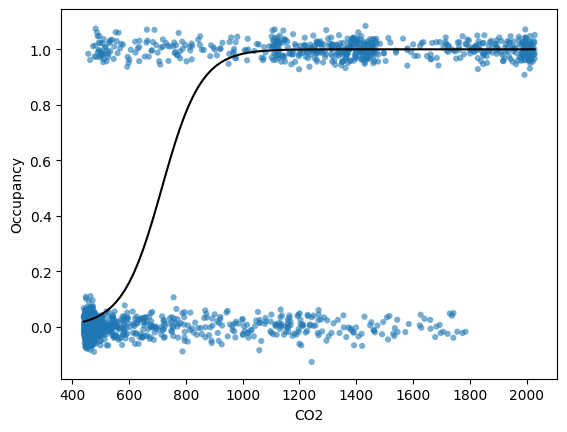

In [38]:
fig, ax = plt.subplots()

ax.scatter(df_test["CO2"], df_test["Occ_Jitter"], s = 20, alpha = 0.6, edgecolors="none")
ax.plot(df_fake["CO2"], df_fake["prob"], color="black")

ax.set_xlabel("CO2")
ax.set_ylabel("Occupancy")

## Question

* What value of "CO2" looks like it would correspond to  p = 0.7?  (Just estimate from looking at the plot.)
* Solve for this value explicitly using logit / log odds and the coefficients of our fit model.

In [35]:
w = clf2.coef_[0][0]
b = clf2.intercept_[0]

co2_07 = (np.log(0.7/0.3) - b) / w
co2_07

np.float64(774.2980183026528)

In [36]:
clf2.predict_proba(pd.DataFrame({"CO2": [co2_07]}))[:, 1]

array([0.7])

## Submission

* When you've completed this assignment, save your work, commit and push your changes to GitHub (including this notebook and any changes to `requirements.txt`), and share the GitHub directory through Gradescope, linked from the left side of Canvas.